# Incremental Capstone: MLOps for Bank Customer Churn Prediction

**Goal:** build an end-to-end MLOps solution that predicts which bank customers are likely to leave, so the retention team can act before they do.

| Task | What it covers | Where the code lives |
|---|---|---|
| 1. Working with churn data | Load, inspect, clean, group, pivot, summarize | This notebook, `src/data_prep.py` |
| 2. Building predictive models | Train four models, compare on Accuracy / Precision / Recall / F1 | `src/train.py` |
| 3. Managing experiments | MLflow tracking, comparison, model registry | `src/train.py`, MLflow UI |
| 4. Operationalizing the model | FastAPI, Docker, monitoring, drift, retraining | `app/main.py`, `Dockerfile`, `src/monitor.py`, `src/retrain.py` |

The notebook is the walkthrough. The reusable code sits in `src/` and `app/` so the same functions run here, from the command line, and inside the container. Where a task depends on one of those files, the file is printed in the notebook so everything can be read in one place.

## Setup

In [1]:
# If any of these are missing in your environment, uncomment and run once:
# %pip install -q mlflow fastapi "uvicorn[standard]" httpx seaborn

In [2]:
import json
import os
import shutil
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# Start with a clean MLflow store so model versions begin at 1 on every full run.
# Set to False to keep run history between notebook runs.
FRESH_START = True
if FRESH_START:
    shutil.rmtree(ROOT / "mlruns", ignore_errors=True)
    (ROOT / "mlflow.db").unlink(missing_ok=True)

def show_file(path, language="python"):
    """Show a project file as a code block that follows the editor theme."""
    display(Markdown(f"**`{path}`**\n\n```{language}\n{(ROOT / path).read_text().rstrip()}\n```"))

print("Project root:", ROOT)
print("Dataset:", config.DATA_PATH.relative_to(ROOT))

Project root: /workspaces/utd-aiml-coursework/notebooks/unit-5/incremental-capstone-mlops
Dataset: data/Churn_Modeling2.csv


---
# Task 1: Working with Churn Data

## 1.1 and 1.2 Import libraries and load the dataset
The libraries were imported in the setup cell above (pandas, numpy, matplotlib, seaborn). The file is loaded exactly as delivered first, so any problems in the raw data are visible before cleaning.

In [3]:
raw = pd.read_csv(config.DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (10000, 14)


,CustomerId,CustomerId.1,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.000,1,1,1,"101,348.880",1
1,2,15647311,Hill,608,Spain,Female,41,1,"83,807.860",1,0,1,"112,542.580",0
2,3,15619304,Onio,502,France,Female,42,8,"159,660.800",3,1,0,"113,931.570",1
3,4,15701354,Boni,699,France,Female,39,1,0.000,2,0,0,"93,826.630",0
4,5,15737888,Mitchell,850,Spain,Female,43,2,"125,510.820",1,1,1,"79,084.100",0


**First inconsistency:** the file has two columns with the header `CustomerId`. Pandas renames the second one to `CustomerId.1`. The first is just a row counter from 1 to 10,000 (it is called `RowNumber` in the standard version of this dataset), and the second holds the real customer IDs. The check below confirms that.

In [4]:
print("First 'CustomerId' column is a 1..N row counter:",
      (raw["CustomerId"] == np.arange(1, len(raw) + 1)).all())
print("Unique values in the real customer ID column:", raw["CustomerId.1"].nunique())

raw = raw.rename(columns={"CustomerId": "RowNumber", "CustomerId.1": "CustomerId"})
raw.columns.tolist()

First 'CustomerId' column is a 1..N row counter: True
Unique values in the real customer ID column: 10000


['RowNumber',
 'CustomerId',
 'Surname',
 'CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

## 1.3 Data types, categorical and numerical features

In [5]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [6]:
feature_summary = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "unique_values": raw.nunique(),
    "example": raw.iloc[0],
})
feature_summary["role"] = "numerical"
feature_summary.loc[["Geography", "Gender"], "role"] = "categorical"
feature_summary.loc[["HasCrCard", "IsActiveMember"], "role"] = "numerical (binary flag)"
feature_summary.loc[["RowNumber", "CustomerId", "Surname"], "role"] = "identifier (dropped)"
feature_summary.loc["Exited", "role"] = "target"
feature_summary

,dtype,unique_values,example,role
RowNumber,int64,10000,1,identifier (dropped)
CustomerId,int64,10000,15634602,identifier (dropped)
Surname,object,2932,Hargrave,identifier (dropped)
CreditScore,int64,460,619,numerical
Geography,object,3,France,categorical
Gender,object,2,Female,categorical
Age,int64,70,42,numerical
Tenure,int64,11,2,numerical
Balance,float64,6382,0.000,numerical
NumOfProducts,int64,4,1,numerical


- **Categorical:** `Geography` (3 countries) and `Gender` (2 values). These get one-hot encoded.
- **Numerical:** `CreditScore`, `Age`, `Tenure`, `Balance`, `NumOfProducts`, `EstimatedSalary`, plus the 0/1 flags `HasCrCard` and `IsActiveMember`. These get standardized.
- **Identifiers:** `RowNumber`, `CustomerId`, and `Surname` say nothing about behavior and would only let a model memorize people, so they are dropped.
- **Target:** `Exited` (1 = the customer left).

## 1.4 Distributions, missing values, and inconsistent values

In [7]:
quality = pd.DataFrame({
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean() * 100).round(2),
})
print("Fully duplicated rows:", raw.duplicated().sum())
print("Duplicated customer IDs:", raw["CustomerId"].duplicated().sum())
quality.T

Fully duplicated rows: 0
Duplicated customer IDs: 0


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
missing,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
missing_%,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


In [8]:
print("Geography values:", sorted(raw["Geography"].unique()))
print("Gender values:   ", sorted(raw["Gender"].unique()))
print()
checks = {
    "Age outside 18 to 100": ((raw["Age"] < 18) | (raw["Age"] > 100)).sum(),
    "CreditScore outside 300 to 850": ((raw["CreditScore"] < 300) | (raw["CreditScore"] > 850)).sum(),
    "Negative Balance": (raw["Balance"] < 0).sum(),
    "Negative EstimatedSalary": (raw["EstimatedSalary"] < 0).sum(),
    "Balance exactly 0": (raw["Balance"] == 0).sum(),
    "CreditScore at the 850 cap": (raw["CreditScore"] == 850).sum(),
    "EstimatedSalary under 1,000": (raw["EstimatedSalary"] < 1000).sum(),
}
pd.Series(checks, name="rows").to_frame()

Geography values: ['France', 'Germany', 'Spain']
Gender values:    ['Female', 'Male']



,rows
Age outside 18 to 100,0
CreditScore outside 300 to 850,0
Negative Balance,0
Negative EstimatedSalary,0
Balance exactly 0,3617
CreditScore at the 850 cap,233
"EstimatedSalary under 1,000",59


In [9]:
raw.drop(columns=["RowNumber", "CustomerId"]).describe().T

,count,mean,std,min,25%,50%,75%,max
CreditScore,"10,000.000",650.529,96.653,350.000,584.000,652.000,718.000,850.000
Age,"10,000.000",38.922,10.488,18.000,32.000,37.000,44.000,92.000
Tenure,"10,000.000",5.013,2.892,0.000,3.000,5.000,7.000,10.000
Balance,"10,000.000","76,485.889","62,397.405",0.000,0.000,"97,198.540","127,644.240","250,898.090"
NumOfProducts,"10,000.000",1.530,0.582,1.000,1.000,1.000,2.000,4.000
HasCrCard,"10,000.000",0.706,0.456,0.000,0.000,1.000,1.000,1.000
IsActiveMember,"10,000.000",0.515,0.500,0.000,0.000,1.000,1.000,1.000
EstimatedSalary,"10,000.000","100,090.240","57,510.493",11.580,"51,002.110","100,193.915","149,388.247","199,992.480"
Exited,"10,000.000",0.204,0.403,0.000,0.000,0.000,0.000,1.000


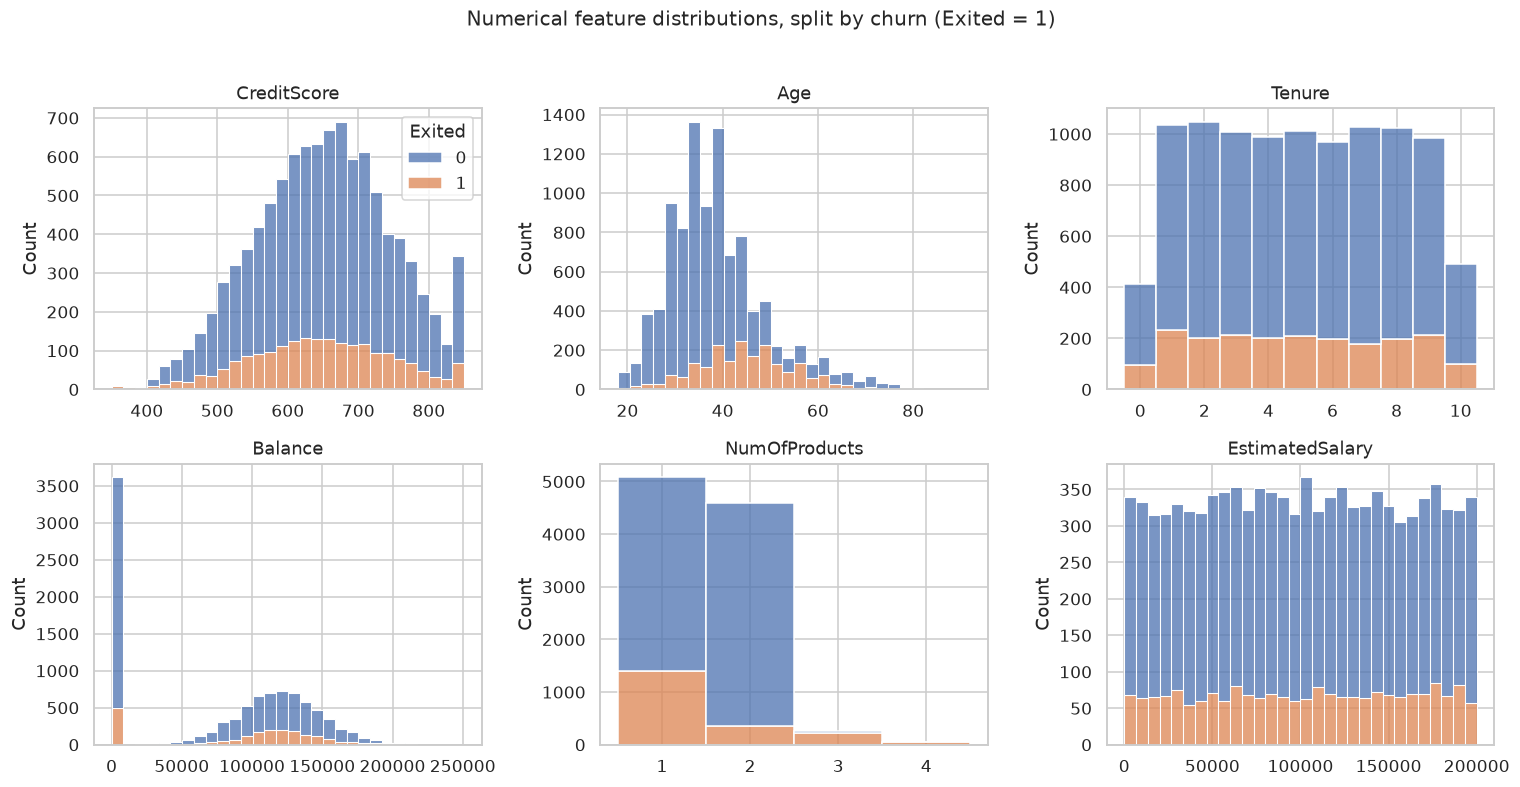

In [10]:
num_cols = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "EstimatedSalary"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), num_cols):
    discrete = raw[col].nunique() < 15
    sns.histplot(data=raw, x=col, hue="Exited", multiple="stack", bins=30 if not discrete else None,
                 discrete=discrete, ax=ax, legend=(col == "CreditScore"))
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Numerical feature distributions, split by churn (Exited = 1)", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

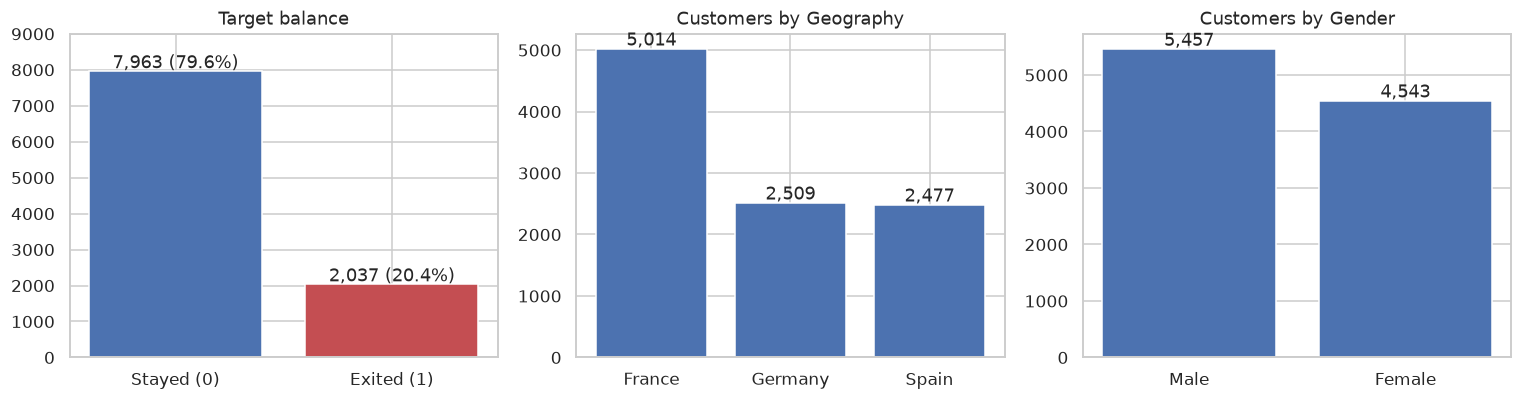

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
churn_counts = raw["Exited"].value_counts().rename({0: "Stayed (0)", 1: "Exited (1)"})
axes[0].bar(churn_counts.index, churn_counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(churn_counts.values):
    axes[0].text(i, v + 80, f"{v:,} ({v / len(raw):.1%})", ha="center")
axes[0].set_title("Target balance")
axes[0].set_ylim(0, 9000)
for ax, col in zip(axes[1:], ["Geography", "Gender"]):
    counts = raw[col].value_counts()
    ax.bar(counts.index, counts.values, color="#4C72B0")
    for i, v in enumerate(counts.values):
        ax.text(i, v + 60, f"{v:,}", ha="center")
    ax.set_title(f"Customers by {col}")
plt.tight_layout()
plt.show()

**What the data quality checks show**

- **No missing values and no duplicate rows or customer IDs.** Nothing needs to be imputed.
- **Header problem:** the duplicated `CustomerId` header (fixed above).
- **Zero balances:** 3,617 customers (36.2%) have a balance of exactly 0. That is too many to be an error. It looks like customers who hold a product other than a deposit account, so the zeros are kept as real values. They are concentrated in France and Spain (see 1.5).
- **Credit score cap:** 233 customers sit at exactly 850, the maximum, so the score is capped rather than wrong.
- **Very low salaries:** 59 customers have an estimated salary under 1,000. `EstimatedSalary` is spread almost perfectly evenly from 0 to 200,000, which is not how real incomes look. It is kept, but it should not be expected to carry much signal.
- **Class imbalance:** only 20.4% of customers churned. A model that predicts "stays" for everyone would be 79.6% accurate and useless, which is why F1 is the selection metric in Task 2 and why the models use balanced class weights.
- **Scale differences:** `Balance` and `EstimatedSalary` run into the hundreds of thousands while `Tenure` and `NumOfProducts` are single digits, so scaling is needed.

## 1.5 Grouping and pivot analysis

In [12]:
df = raw.copy()

def churn_by(col):
    out = df.groupby(col, observed=True)["Exited"].agg(customers="count", churned="sum", churn_rate="mean")
    out["share_of_customers"] = out["customers"] / len(df)
    return out

display(churn_by("Geography"))
display(churn_by("Gender"))

,customers,churned,churn_rate,share_of_customers
Geography,,,,
France,5014,810,0.162,0.501
Germany,2509,814,0.324,0.251
Spain,2477,413,0.167,0.248


,customers,churned,churn_rate,share_of_customers
Gender,,,,
Female,4543,1139,0.251,0.454
Male,5457,898,0.165,0.546


In [13]:
pivot_rate = df.pivot_table(index="Geography", columns="Gender", values="Exited", aggfunc="mean", margins=True, margins_name="All")
pivot_count = df.pivot_table(index="Geography", columns="Gender", values="Exited", aggfunc="count", margins=True, margins_name="All")
print("Churn rate by Geography and Gender")
display(pivot_rate)
print("Customer count by Geography and Gender")
display(pivot_count)

Churn rate by Geography and Gender


Gender,Female,Male,All
Geography,,,
France,0.203,0.127,0.162
Germany,0.376,0.278,0.324
Spain,0.212,0.131,0.167
All,0.251,0.165,0.204


Customer count by Geography and Gender


Gender,Female,Male,All
Geography,,,
France,2261,2753,5014
Germany,1193,1316,2509
Spain,1089,1388,2477
All,4543,5457,10000


In [14]:
geo_profile = df.groupby("Geography").agg(
    customers=("Exited", "count"),
    churn_rate=("Exited", "mean"),
    avg_age=("Age", "mean"),
    avg_balance=("Balance", "mean"),
    zero_balance_share=("Balance", lambda s: (s == 0).mean()),
    avg_products=("NumOfProducts", "mean"),
    active_share=("IsActiveMember", "mean"),
)
geo_profile

,customers,churn_rate,avg_age,avg_balance,zero_balance_share,avg_products,active_share
Geography,,,,,,,
France,5014,0.162,38.512,"62,092.637",0.482,1.531,0.517
Germany,2509,0.324,39.772,"119,730.116",0.000,1.520,0.497
Spain,2477,0.167,38.891,"61,818.148",0.484,1.539,0.530


In [15]:
df["AgeBand"] = pd.cut(df["Age"], bins=[17, 30, 40, 50, 60, 100], labels=["18-30", "31-40", "41-50", "51-60", "61+"])
display(churn_by("AgeBand"))
display(churn_by("NumOfProducts"))
display(churn_by("IsActiveMember"))

print("Churn rate by AgeBand and IsActiveMember")
df.pivot_table(index="AgeBand", columns="IsActiveMember", values="Exited", aggfunc="mean", observed=True)

,customers,churned,churn_rate,share_of_customers
AgeBand,,,,
18-30,1968,148,0.075,0.197
31-40,4451,538,0.121,0.445
41-50,2320,788,0.340,0.232
51-60,797,448,0.562,0.080
61+,464,115,0.248,0.046


,customers,churned,churn_rate,share_of_customers
NumOfProducts,,,,
1,5084,1409,0.277,0.508
2,4590,348,0.076,0.459
3,266,220,0.827,0.027
4,60,60,1.000,0.006


,customers,churned,churn_rate,share_of_customers
IsActiveMember,,,,
0,4849,1302,0.269,0.485
1,5151,735,0.143,0.515


Churn rate by AgeBand and IsActiveMember


IsActiveMember,0,1
AgeBand,,
18-30,0.101,0.051
31-40,0.149,0.092
41-50,0.416,0.254
51-60,0.857,0.347
61+,0.820,0.112


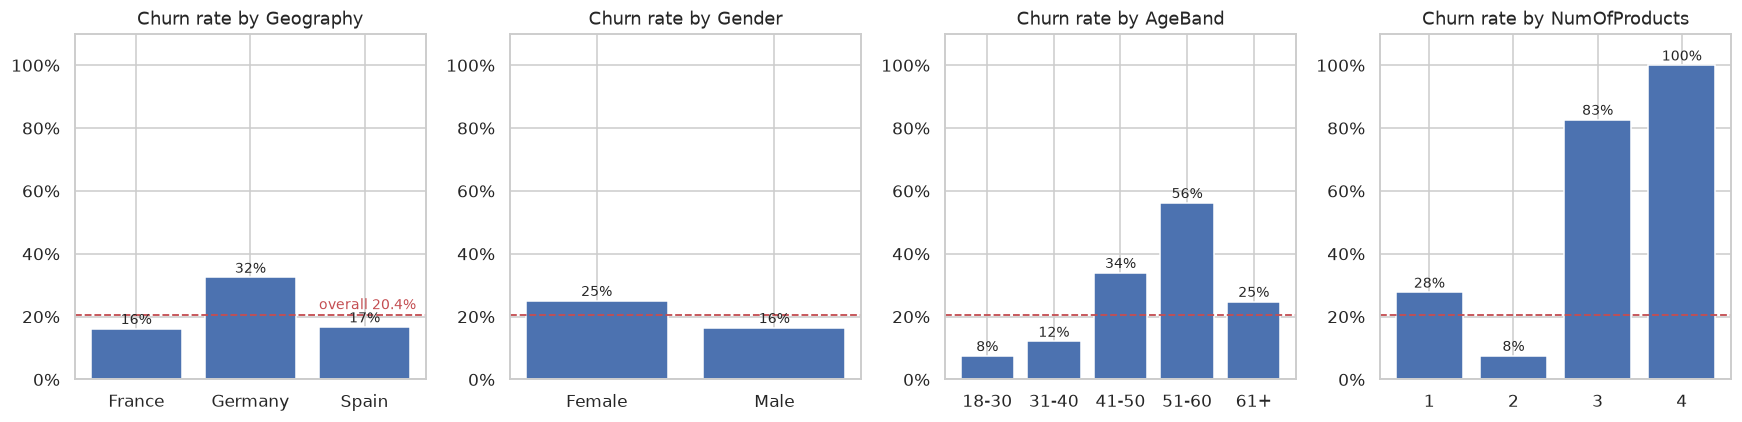

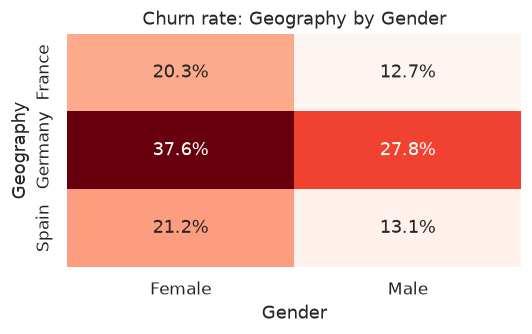

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
overall = df["Exited"].mean()
for ax, col in zip(axes, ["Geography", "Gender", "AgeBand", "NumOfProducts"]):
    rates = df.groupby(col, observed=True)["Exited"].mean()
    ax.bar(rates.index.astype(str), rates.values, color="#4C72B0")
    ax.axhline(overall, color="#C44E52", linestyle="--", linewidth=1.2)
    for i, v in enumerate(rates.values):
        ax.text(i, v + 0.015, f"{v:.0%}", ha="center", fontsize=9)
    ax.set_title(f"Churn rate by {col}")
    ax.set_ylim(0, 1.1)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].text(2.45, overall + 0.02, f"overall {overall:.1%}", color="#C44E52", ha="right", fontsize=9)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(5, 3.2))
sns.heatmap(pivot_rate.drop(index="All", columns="All"), annot=True, fmt=".1%", cmap="Reds", cbar=False, ax=ax)
ax.set_title("Churn rate: Geography by Gender")
plt.tight_layout()
plt.show()

## 1.6 Summary statistics for churn patterns

Average profile of customers who stayed (0) vs left (1)


Exited,Stayed,Exited
CreditScore,651.853,645.351
Age,37.408,44.838
Tenure,5.033,4.933
Balance,"72,745.297","91,108.539"
NumOfProducts,1.544,1.475
HasCrCard,0.707,0.699
IsActiveMember,0.555,0.361
EstimatedSalary,"99,738.392","101,465.678"


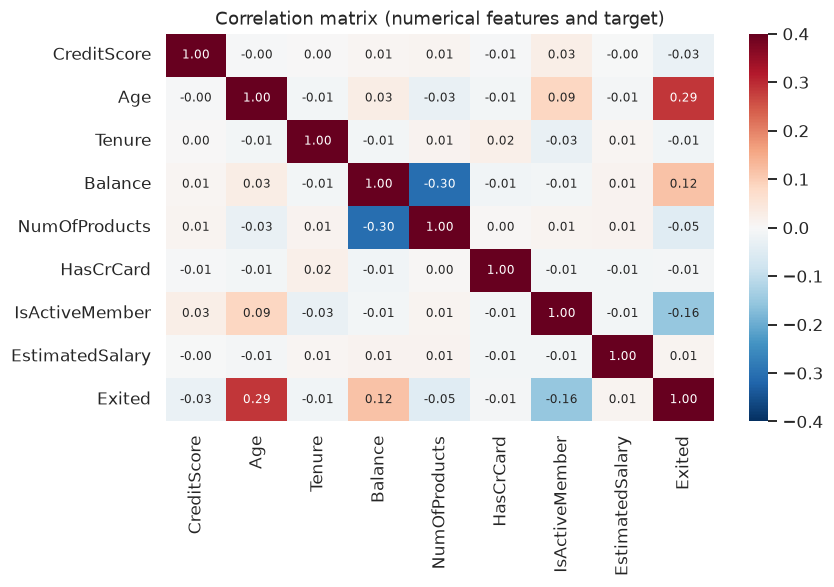

,correlation_with_Exited
Age,0.285
IsActiveMember,-0.156
Balance,0.119
NumOfProducts,-0.048
CreditScore,-0.027
Tenure,-0.014
EstimatedSalary,0.012
HasCrCard,-0.007


In [17]:
print("Average profile of customers who stayed (0) vs left (1)")
display(df.groupby("Exited")[["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts",
                              "HasCrCard", "IsActiveMember", "EstimatedSalary"]].mean().T
          .rename(columns={0: "Stayed", 1: "Exited"}))

corr = df.select_dtypes("number").drop(columns=["RowNumber", "CustomerId"]).corr()
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.4, vmax=0.4, ax=ax, annot_kws={"size": 8})
ax.set_title("Correlation matrix (numerical features and target)")
plt.tight_layout()
plt.show()

corr["Exited"].drop("Exited").sort_values(key=abs, ascending=False).to_frame("correlation_with_Exited")

## 1.7 Insights for model training and reporting

**Churn patterns**

1. **Germany is the problem market.** Germany's churn rate is 32.4%, about double France (16.2%) and Spain (16.7%). German customers also carry no zero balances at all and a much higher average balance, so the bank is losing its higher-balance customers there.
2. **Women churn more than men** (25.1% vs 16.5%), and the gap holds in every country. German women are the highest-risk group in the pivot at 37.6%.
3. **Age is the strongest single driver** (correlation 0.29). Churn climbs from 7.5% for customers 18 to 30 up to 56.2% for ages 51 to 60, then falls back to 24.8% past 60. That rise and fall is not a straight line, which favors tree-based models over a linear one.
4. **Number of products is strongly non-linear.** Customers with 2 products rarely leave (7.6%). Customers with 1 product leave at 27.7%, and those with 3 or 4 products leave at 82.7% and 100%. Only 326 customers hold 3 or more, but they are nearly all churners.
5. **Inactive members churn at almost twice the rate** of active ones (26.9% vs 14.3%). The combination with age is the sharpest segment in the data: inactive customers over 50 churn at more than 80%, while active customers over 60 churn at only 11.2%.
6. **Low-signal features:** `HasCrCard`, `Tenure`, `EstimatedSalary`, and `CreditScore` barely move the churn rate on their own.

**What this means for modeling**

- Drop `RowNumber`, `CustomerId`, and `Surname`.
- One-hot encode `Geography` and `Gender`, standardize the numerical features.
- Use a stratified train/test split so both sets keep the 20.4% churn rate.
- Handle the class imbalance with balanced class weights, and select the model on **F1** rather than accuracy.
- Expect tree ensembles to beat logistic regression, because the age and product effects are non-linear.

**For the retention team:** the first places to look are German customers, inactive customers over 40, and anyone holding 3 or more products.

## 1.8 Prepare the data for modeling
The cleaning, encoding, and scaling steps are wrapped in functions in `src/data_prep.py` so training, retraining, and monitoring all prepare data the same way. The encoder and scaler live **inside the model pipeline**, so they are fit on training data only (no leakage) and the deployed API can accept raw customer records.

In [18]:
show_file("src/data_prep.py", "python")

**`src/data_prep.py`**

```python
"""Task 1 helpers: load, clean, encode, and scale the raw banking data."""
from __future__ import annotations

from pathlib import Path

import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src import config


def load_raw(path: str | Path = config.DATA_PATH) -> pd.DataFrame:
    """Load the CSV exactly as delivered."""
    return pd.read_csv(path)


def clean(df: pd.DataFrame) -> pd.DataFrame:
    """Fix header problems, drop identifier columns, and tidy values.

    The delivered file has two columns named ``CustomerId``. The first one is
    really a row counter (1 to 10,000), so pandas reads the pair as
    ``CustomerId`` and ``CustomerId.1``. Neither one, nor ``Surname``, carries
    any signal about churn, so all identifier columns are dropped.
    """
    df = df.copy()
    if "CustomerId.1" in df.columns:
        df = df.rename(columns={"CustomerId": "RowNumber", "CustomerId.1": "CustomerId"})
    df = df.drop(columns=["RowNumber", "CustomerId", "Surname"], errors="ignore")

    for col in config.CATEGORICAL_FEATURES:
        df[col] = df[col].astype(str).str.strip().str.title()

    df = df.drop_duplicates().dropna(subset=config.FEATURES + [config.TARGET])
    df[config.TARGET] = df[config.TARGET].astype(int)
    return df.reset_index(drop=True)


def load_clean(path: str | Path = config.DATA_PATH) -> pd.DataFrame:
    return clean(load_raw(path))


def build_preprocessor() -> ColumnTransformer:
    """One-hot encode the categoricals and standardize the numerics."""
    return ColumnTransformer(
        transformers=[
            ("cat", OneHotEncoder(handle_unknown="ignore"), config.CATEGORICAL_FEATURES),
            ("num", StandardScaler(), config.NUMERIC_FEATURES),
        ]
    )


def split(df: pd.DataFrame):
    """Stratified train/test split so both sets keep the ~20% churn rate."""
    X, y = df[config.FEATURES], df[config.TARGET]
    return train_test_split(
        X, y, test_size=config.TEST_SIZE, stratify=y, random_state=config.RANDOM_STATE
    )
```

In [19]:
from src.data_prep import build_preprocessor, load_clean, split

clean_df = load_clean()
X_train, X_test, y_train, y_test = split(clean_df)

print("Clean data shape:", clean_df.shape)
print(f"Train: {X_train.shape}, churn rate {y_train.mean():.3f}")
print(f"Test:  {X_test.shape}, churn rate {y_test.mean():.3f}")

prep = build_preprocessor().fit(X_train)
encoded = pd.DataFrame(prep.transform(X_train), columns=prep.get_feature_names_out())
print("\nAfter encoding and scaling:", encoded.shape)
encoded.head()

Clean data shape: (10000, 11)
Train: (8000, 10), churn rate 0.204
Test:  (2000, 10), churn rate 0.203

After encoding and scaling: (8000, 13)


,cat__Geography_France,cat__Geography_Germany,cat__Geography_Spain,cat__Gender_Female,cat__Gender_Male,num__CreditScore,num__Age,num__Tenure,num__Balance,num__NumOfProducts,num__HasCrCard,num__IsActiveMember,num__EstimatedSalary
0,1.000,0.000,0.000,0.000,1.000,1.059,1.715,0.685,-1.226,-0.910,0.641,-1.030,1.042
1,0.000,1.000,0.000,0.000,1.000,0.914,-0.660,-0.696,0.413,-0.910,0.641,-1.030,-0.624
2,0.000,1.000,0.000,1.000,0.000,1.079,-0.185,-1.732,0.602,0.809,0.641,0.971,0.308
3,1.000,0.000,0.000,0.000,1.000,-0.929,-0.185,-0.006,-1.226,0.809,0.641,-1.030,-0.290
4,0.000,1.000,0.000,0.000,1.000,0.427,0.955,0.339,0.548,0.809,-1.560,0.971,0.135


---
# Task 2: Building Predictive Models

Four models are trained on the same split and the same preprocessing:

| Model | Why it is included |
|---|---|
| Logistic Regression | Simple, interpretable baseline |
| Decision Tree | Captures the non-linear age and product effects, easy to explain |
| Random Forest | Bagged trees, usually strong on tabular data |
| Gradient Boosting | Boosted trees, usually the strongest on tabular data |

Every model is trained with balanced class weights so the 20% churn class is not ignored. Each is scored on the held-out test set with **Accuracy, Precision, Recall, and F1**, and the best F1 wins.

The training code is in `src/train.py`. The same function also does the MLflow logging for Task 3, so each model is trained once and tracked at the same time.

In [20]:
show_file("src/train.py", "python")

**`src/train.py`**

```python
"""Tasks 2 and 3: train several churn models, track them in MLflow,
register the best one (by F1), and save the artifacts the API serves.

Run from the project root:
    python -m src.train
"""
from __future__ import annotations

import json
import logging
import platform
import warnings
from datetime import datetime, timezone

import joblib
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import sklearn
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight

from src import config
from src.data_prep import build_preprocessor, load_clean, split


def get_models() -> dict:
    """Candidate models. Churners are only ~20% of customers, so every model
    is trained with balanced class weights (see ``fit_pipeline``)."""
    rs = config.RANDOM_STATE
    return {
        "logistic_regression": LogisticRegression(max_iter=1000, C=1.0, random_state=rs),
        "decision_tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=rs),
        "random_forest": RandomForestClassifier(
            n_estimators=300, max_depth=10, min_samples_leaf=5, n_jobs=-1, random_state=rs
        ),
        "gradient_boosting": GradientBoostingClassifier(
            n_estimators=200, learning_rate=0.1, max_depth=3, random_state=rs
        ),
    }


def fit_pipeline(model, X, y, sample_weight=None) -> Pipeline:
    """Preprocessing + model in one pipeline, so the API can take raw rows."""
    weights = compute_sample_weight("balanced", y)
    if sample_weight is not None:
        weights = weights * np.asarray(sample_weight)
    pipe = Pipeline([("prep", build_preprocessor()), ("model", model)])
    pipe.fit(X, y, model__sample_weight=weights)
    return pipe


def evaluate(pipe: Pipeline, X, y) -> dict:
    pred = pipe.predict(X)
    proba = pipe.predict_proba(X)[:, 1]
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, proba),
    }


def setup_mlflow(experiment_name: str = config.EXPERIMENT_NAME) -> None:
    # Quiet MLflow's routine notices (integer-schema hints, pickle reminders).
    logging.getLogger("mlflow").setLevel(logging.ERROR)
    warnings.filterwarnings("ignore", module="mlflow")
    mlflow.set_tracking_uri(config.TRACKING_URI)
    if mlflow.get_experiment_by_name(experiment_name) is None:
        mlflow.create_experiment(experiment_name, artifact_location=config.ARTIFACT_ROOT)
    mlflow.set_experiment(experiment_name)


def _log_model(pipe, X_example):
    """Log a model to MLflow. Works on both MLflow 2.x and 3.x."""
    signature = infer_signature(X_example, pipe.predict(X_example))
    # cloudpickle keeps this working on every MLflow version (newer releases
    # default to skops, which refuses tree models unless types are whitelisted).
    kwargs = dict(signature=signature, input_example=X_example.head(3),
                  serialization_format="cloudpickle")
    try:
        return mlflow.sklearn.log_model(pipe, name="model", **kwargs)
    except TypeError:  # MLflow 2.x uses artifact_path
        return mlflow.sklearn.log_model(pipe, artifact_path="model", **kwargs)


def reference_stats(X: pd.DataFrame) -> dict:
    """Training-set distributions, saved so monitoring can measure drift."""
    stats = {"numeric": {}, "categorical": {}}
    for col in config.NUMERIC_FEATURES:
        edges = np.unique(np.quantile(X[col], np.linspace(0, 1, 11)))
        stats["numeric"][col] = {
            "mean": float(X[col].mean()),
            "std": float(X[col].std()),
            "bin_edges": [float(e) for e in edges],
        }
    for col in config.CATEGORICAL_FEATURES:
        stats["categorical"][col] = X[col].value_counts(normalize=True).round(6).to_dict()
    return stats


def train_and_track(
    X_train, y_train, X_test, y_test,
    sample_weight=None, run_tag: str = "initial_training", register: bool = True, deploy: bool = True,
) -> dict:
    """Train every candidate, log each as its own MLflow run, register and
    save the best one by F1. Returns a summary dict.

    ``deploy=False`` registers the new version in MLflow but leaves the model
    file the API serves, and the "champion" alias, untouched. The monitoring
    simulation uses that so a made-up drift scenario never replaces the real model."""
    setup_mlflow()
    results, pipes, infos = [], {}, {}

    for name, model in get_models().items():
        with mlflow.start_run(run_name=name) as run:
            pipe = fit_pipeline(model, X_train, y_train, sample_weight)
            metrics = evaluate(pipe, X_test, y_test)

            mlflow.set_tags({"stage": run_tag, "model_family": type(model).__name__})
            mlflow.log_params({k: v for k, v in model.get_params().items() if v is not None})
            mlflow.log_params({
                "class_weighting": "balanced",
                "n_train_rows": len(X_train),
                "n_test_rows": len(X_test),
                "features": ",".join(config.FEATURES),
            })
            mlflow.log_metrics(metrics)
            infos[name] = _log_model(pipe, X_test)

            pipes[name] = pipe
            results.append({"model": name, "run_id": run.info.run_id, **metrics})

    results_df = pd.DataFrame(results).sort_values("f1", ascending=False).reset_index(drop=True)
    best = results_df.iloc[0]
    best_name, best_pipe = best["model"], pipes[best["model"]]

    version = None
    if register:
        mv = mlflow.register_model(infos[best_name].model_uri, config.REGISTERED_MODEL_NAME)
        version = int(mv.version)
        client = MlflowClient()
        if deploy:
            client.set_registered_model_alias(config.REGISTERED_MODEL_NAME, "champion", mv.version)
        client.set_model_version_tag(config.REGISTERED_MODEL_NAME, mv.version, "stage", run_tag)
        client.set_model_version_tag(
            config.REGISTERED_MODEL_NAME, mv.version, "f1", f"{best['f1']:.4f}"
        )

    if deploy:
        save_artifacts(best_pipe, best_name, best, X_train, version, run_tag)
    return {
        "results": results_df, "best_name": best_name, "best_pipeline": best_pipe,
        "best_metrics": {k: float(best[k]) for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
        "registered_version": version,
    }


def save_artifacts(pipe, name, metrics_row, X_train, version, run_tag) -> None:
    """Save what the FastAPI service needs: the model, its metadata, and the
    exact library versions it was trained with (used by the Dockerfile)."""
    config.MODEL_DIR.mkdir(exist_ok=True)
    joblib.dump(pipe, config.MODEL_PATH, compress=3)

    metadata = {
        "model_name": name,
        "registered_model": config.REGISTERED_MODEL_NAME,
        "registered_version": version,
        "stage": run_tag,
        "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "metrics": {k: round(float(metrics_row[k]), 4)
                    for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]},
        "features": config.FEATURES,
        "n_train_rows": int(len(X_train)),
        "python_version": platform.python_version(),
        "reference_stats": reference_stats(X_train),
    }
    config.METADATA_PATH.write_text(json.dumps(metadata, indent=2))

    config.SERVING_REQS_PATH.write_text(
        "# Written by src/train.py. Pins the libraries the saved model needs.\n"
        f"scikit-learn=={sklearn.__version__}\n"
        f"pandas=={pd.__version__}\n"
        f"numpy=={np.__version__}\n"
        f"joblib=={joblib.__version__}\n"
        "fastapi\nuvicorn[standard]\n"
    )


def main() -> None:
    df = load_clean()
    X_train, X_test, y_train, y_test = split(df)
    out = train_and_track(X_train, y_train, X_test, y_test)
    print(out["results"].drop(columns="run_id").round(4).to_string(index=False))
    print(f"\nBest model by F1: {out['best_name']} "
          f"(registered as {config.REGISTERED_MODEL_NAME} v{out['registered_version']})")
    print(f"Saved to {config.MODEL_PATH}")


if __name__ == "__main__":
    main()
```

In [21]:
from src.train import train_and_track

training = train_and_track(X_train, y_train, X_test, y_test, run_tag="initial_training")

results = training["results"]
results.drop(columns="run_id").style.format(precision=4).highlight_max(
    subset=["accuracy", "precision", "recall", "f1", "roc_auc"],
    props="background-color: #2e7d32; color: white; font-weight: bold")

Successfully registered model 'churn-prediction-model'.
Created version '1' of model 'churn-prediction-model'.


,model,accuracy,precision,recall,f1,roc_auc
0,random_forest,0.8125,0.5285,0.7297,0.6130,0.8622
1,gradient_boosting,0.8040,0.5126,0.7518,0.6096,0.8649
2,decision_tree,0.7615,0.4506,0.7838,0.5722,0.8417
3,logistic_regression,0.7135,0.3872,0.7002,0.4987,0.7772


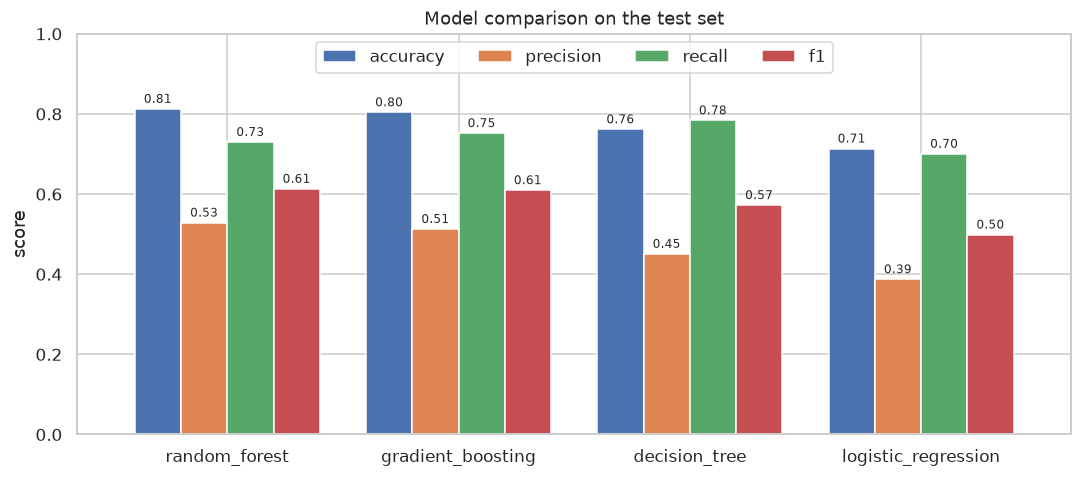

In [22]:
metric_cols = ["accuracy", "precision", "recall", "f1"]
ax = results.set_index("model")[metric_cols].plot(kind="bar", figsize=(10, 4.5), width=0.8)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_title("Model comparison on the test set")
ax.set_ylabel("score")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.legend(ncol=4, loc="upper center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Best model by F1: random_forest

              precision    recall  f1-score   support

      Stayed      0.924     0.834     0.876      1593
      Exited      0.528     0.730     0.613       407

    accuracy                          0.812      2000
   macro avg      0.726     0.782     0.745      2000
weighted avg      0.843     0.812     0.823      2000



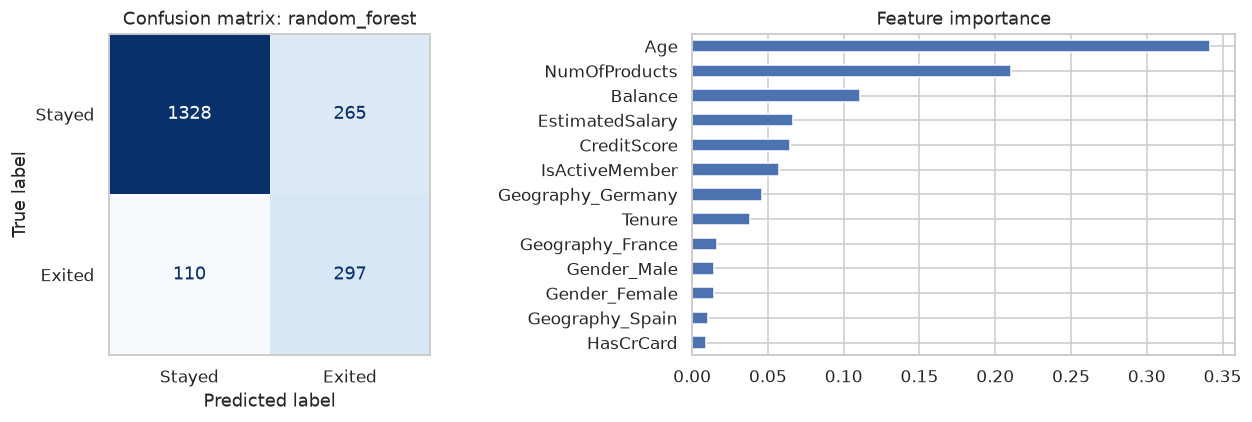

In [23]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

best_name = training["best_name"]
best_model = training["best_pipeline"]
print(f"Best model by F1: {best_name}\n")

y_pred = best_model.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Stayed", "Exited"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Stayed", "Exited"],
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title(f"Confusion matrix: {best_name}")
axes[0].grid(False)

model_step = best_model.named_steps["model"]
names = best_model.named_steps["prep"].get_feature_names_out()
if hasattr(model_step, "feature_importances_"):
    importance = pd.Series(model_step.feature_importances_, index=names)
else:
    importance = pd.Series(np.abs(model_step.coef_[0]), index=names)
importance.index = importance.index.str.replace("cat__|num__", "", regex=True)
importance.sort_values().plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_title("Feature importance")
plt.tight_layout()
plt.show()

In [24]:
print("Saved model artifacts:")
for path in sorted(config.MODEL_DIR.iterdir()):
    print(f"  {path.relative_to(ROOT)}  ({path.stat().st_size / 1024:,.1f} KB)")

metadata = json.loads(config.METADATA_PATH.read_text())
{k: v for k, v in metadata.items() if k != "reference_stats"}

Saved model artifacts:
  models/churn_model.joblib  (3,897.6 KB)
  models/metadata.json  (2.9 KB)
  models/serving-requirements.txt  (0.2 KB)


{'model_name': 'random_forest',
 'registered_model': 'churn-prediction-model',
 'registered_version': 1,
 'stage': 'initial_training',
 'trained_at': '2026-11-10T22:46:40+00:00',
 'metrics': {'accuracy': 0.8125,
  'precision': 0.5285,
  'recall': 0.7297,
  'f1': 0.613,
  'roc_auc': 0.8622},
 'features': ['Geography',
  'Gender',
  'CreditScore',
  'Age',
  'Tenure',
  'Balance',
  'NumOfProducts',
  'HasCrCard',
  'IsActiveMember',
  'EstimatedSalary'],
 'n_train_rows': 8000,
 'python_version': '3.12.3'}

In [25]:
from IPython.display import Markdown
from sklearn.metrics import confusion_matrix

r = results.set_index("model")
runner_up = r.index[1]
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
top3 = ", ".join(importance.sort_values(ascending=False).head(3).index)

display(Markdown(f"""
**Task 2 results**

- **Best model by F1: `{best_name}`** with F1 {r.loc[best_name, 'f1']:.3f} (accuracy {r.loc[best_name, 'accuracy']:.3f}, precision {r.loc[best_name, 'precision']:.3f}, recall {r.loc[best_name, 'recall']:.3f}). The runner-up is `{runner_up}` at F1 {r.loc[runner_up, 'f1']:.3f}.
- Logistic regression comes last at F1 {r.loc['logistic_regression', 'f1']:.3f}. That matches the EDA: the age and product-count effects are not straight lines, and a linear model cannot follow them without extra feature engineering.
- On the 2,000 test customers, the best model catches **{tp} of the {tp + fn} customers who actually left** ({tp / (tp + fn):.0%}). The cost is {fp} false alarms, customers flagged who would have stayed. For retention work that trade is usually acceptable, because a missed churner costs more than an unneeded retention offer.
- The most important features are {top3}, which lines up with the patterns found in Task 1.
- Accuracy alone would have been misleading here. Predicting "stays" for everyone scores {1 - y_test.mean():.1%} accuracy with an F1 of 0.
"""))


**Task 2 results**

- **Best model by F1: `random_forest`** with F1 0.613 (accuracy 0.812, precision 0.528, recall 0.730). The runner-up is `gradient_boosting` at F1 0.610.
- Logistic regression comes last at F1 0.499. That matches the EDA: the age and product-count effects are not straight lines, and a linear model cannot follow them without extra feature engineering.
- On the 2,000 test customers, the best model catches **297 of the 407 customers who actually left** (73%). The cost is 265 false alarms, customers flagged who would have stayed. For retention work that trade is usually acceptable, because a missed churner costs more than an unneeded retention offer.
- The most important features are Age, NumOfProducts, Balance, which lines up with the patterns found in Task 1.
- Accuracy alone would have been misleading here. Predicting "stays" for everyone scores 79.7% accuracy with an F1 of 0.


**Saved artifacts** (in `models/`):
- `churn_model.joblib`: the full pipeline (encoder + scaler + model), which is what the API loads.
- `metadata.json`: model name, version, metrics, feature list, and the training-set distributions used later for drift checks.
- `serving-requirements.txt`: the exact library versions the model was trained with, so the Docker image installs matching versions.

---
# Task 3: Managing and Comparing Experiments with MLflow

The training call in Task 2 already did the tracking. For **every model**, `train_and_track` opened an MLflow run and automatically recorded:

- **Parameters:** every hyperparameter of the model, the class weighting, row counts, and the feature list
- **Metrics:** accuracy, precision, recall, F1, and ROC AUC
- **Tags:** the training stage and model family
- **Model artifact:** the fitted pipeline, with an input/output signature and an input example

MLflow is set up with a local SQLite database (`mlflow.db`) as the tracking store. A database backend is what makes the **Model Registry** available locally.

In [26]:
import mlflow
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri(config.TRACKING_URI)
client = MlflowClient()
experiment = mlflow.get_experiment_by_name(config.EXPERIMENT_NAME)
print("Tracking URI:", config.TRACKING_URI)
print("Experiment:  ", experiment.name, "(id", experiment.experiment_id + ")")

runs = mlflow.search_runs(experiment_ids=[experiment.experiment_id], order_by=["metrics.f1 DESC"])
run_table = runs[["tags.mlflow.runName", "run_id", "status", "metrics.accuracy", "metrics.precision",
                  "metrics.recall", "metrics.f1", "metrics.roc_auc"]]
run_table.columns = [c.replace("tags.mlflow.", "").replace("metrics.", "") for c in run_table.columns]
run_table

Tracking URI: sqlite:////workspaces/utd-aiml-coursework/notebooks/unit-5/incremental-capstone-mlops/mlflow.db
Experiment:   churn-prediction (id 1)


,runName,run_id,status,accuracy,precision,recall,f1,roc_auc
0,random_forest,13e96dc1ac5c4eae8576a45b4879607c,FINISHED,0.812,0.528,0.730,0.613,0.862
1,gradient_boosting,522874e910824a93a5628585b7eb90d2,FINISHED,0.804,0.513,0.752,0.610,0.865
2,decision_tree,f95a75ed0a064c6fa637d04dcb6dfe5e,FINISHED,0.761,0.451,0.784,0.572,0.842
3,logistic_regression,0ee06710f5b64447862ded9c5a32a1b3,FINISHED,0.714,0.387,0.700,0.499,0.777


In [27]:
# Parameters MLflow recorded for the best run
best_run = client.get_run(runs.iloc[0]["run_id"])
print("Run:", best_run.info.run_name)
pd.Series(best_run.data.params, name="value").sort_index().to_frame()

Run: random_forest


,value
bootstrap,True
ccp_alpha,0.0
class_weighting,balanced
criterion,gini
features,"Geography,Gender,CreditScore,Age,Tenure,Balanc..."
max_depth,10
max_features,sqrt
min_impurity_decrease,0.0
min_samples_leaf,5
min_samples_split,2


## Comparing runs visually

The same comparison the MLflow UI shows, built here from the data MLflow stored:

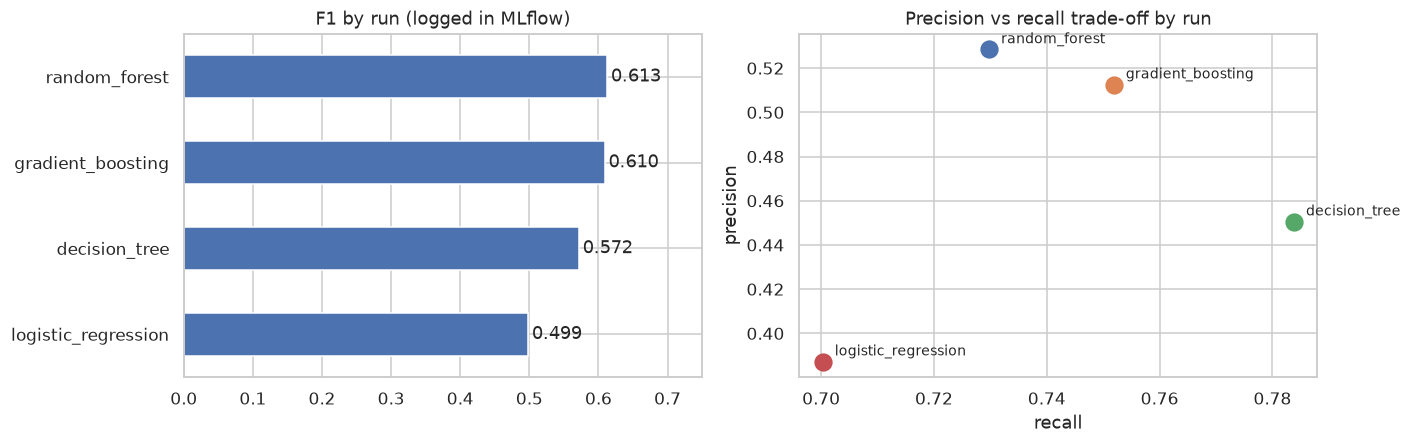

In [28]:
plot_df = run_table.set_index("runName")[["accuracy", "precision", "recall", "f1"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

plot_df["f1"].sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0")
for i, v in enumerate(plot_df["f1"].sort_values()):
    axes[0].text(v + 0.005, i, f"{v:.3f}", va="center")
axes[0].set_title("F1 by run (logged in MLflow)")
axes[0].set_xlim(0, 0.75)
axes[0].set_ylabel("")

for name, row in plot_df.iterrows():
    axes[1].scatter(row["recall"], row["precision"], s=120)
    axes[1].annotate(name, (row["recall"], row["precision"]), textcoords="offset points", xytext=(8, 4), fontsize=9)
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision vs recall trade-off by run")
plt.tight_layout()
plt.show()

### Opening the MLflow UI

From a terminal in the project folder:

```bash
mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```

Then open http://localhost:5000 (in a dev container, VS Code forwards the port automatically).

1. Open the **churn-prediction** experiment.
2. Tick the checkboxes next to all four runs and click **Compare**.
3. Use the **parallel coordinates plot**, **scatter plot**, and **bar charts** to compare accuracy, precision, recall, and F1 side by side.
4. Open the **Models** tab to see **churn-prediction-model** and its versions.

## Registering the best model

The best run by F1 was registered automatically as `churn-prediction-model`, and the alias `champion` points to the version that is deployed. Every retraining adds a new version, so there is a full history of what was deployed and when.

In [29]:
champion_version = int(client.get_model_version_by_alias(config.REGISTERED_MODEL_NAME, "champion").version)
versions = client.search_model_versions(f"name='{config.REGISTERED_MODEL_NAME}'")
registry = pd.DataFrame([{
    "name": v.name,
    "version": int(v.version),
    "aliases": "champion" if int(v.version) == champion_version else "",
    "stage_tag": v.tags.get("stage", ""),
    "f1": v.tags.get("f1", ""),
    "run_id": v.run_id,
} for v in versions]).sort_values("version")
display(registry)

# Load the registered champion straight from the registry and confirm it predicts
champion = mlflow.sklearn.load_model(f"models:/{config.REGISTERED_MODEL_NAME}@champion")
print("Champion loaded from the registry. Predictions on 5 test rows:", champion.predict(X_test.head()).tolist())

,name,version,aliases,stage_tag,f1,run_id
0,churn-prediction-model,1,champion,initial_training,0.6130,13e96dc1ac5c4eae8576a45b4879607c


Champion loaded from the registry. Predictions on 5 test rows: [0, 0, 0, 0, 0]


---
# Task 4: Operationalizing the Model

## 4.1 Deploying with FastAPI

`app/main.py` loads the saved pipeline once at startup and exposes:

| Endpoint | Purpose |
|---|---|
| `GET /health` | Liveness check (used by Docker's health check) |
| `GET /model-info` | Which model and version is being served, with its metrics |
| `POST /predict` | Real-time prediction for one customer |
| `POST /predict/batch` | Predictions for up to 1,000 customers |
| `GET /stats` | Running count of predictions and predicted churn rate |

Inputs are validated with Pydantic, so a bad value (for example a country the model never saw) returns a clear 422 error instead of a silent bad prediction. Every prediction is appended to `logs/predictions.jsonl`, which is the raw material for monitoring.

In [30]:
show_file("app/main.py", "python")

**`app/main.py`**

```python
"""Task 4 (steps 1 and 3): FastAPI service for real-time churn prediction.

Run locally from the project root:
    uvicorn app.main:app --reload --port 8000
Interactive docs: http://localhost:8000/docs
"""
from __future__ import annotations

import json
import os
from contextlib import asynccontextmanager
from datetime import datetime, timezone
from pathlib import Path
from typing import Literal

import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

ROOT = Path(__file__).resolve().parents[1]
MODEL_PATH = Path(os.getenv("MODEL_PATH", ROOT / "models" / "churn_model.joblib"))
METADATA_PATH = Path(os.getenv("METADATA_PATH", ROOT / "models" / "metadata.json"))
PREDICTION_LOG = Path(os.getenv("PREDICTION_LOG", ROOT / "logs" / "predictions.jsonl"))

state: dict = {}


@asynccontextmanager
async def lifespan(app: FastAPI):
    """Load the model once at startup."""
    if MODEL_PATH.exists():
        state["model"] = joblib.load(MODEL_PATH)
        state["metadata"] = json.loads(METADATA_PATH.read_text()) if METADATA_PATH.exists() else {}
    state["served"] = 0
    state["predicted_churn"] = 0
    yield
    state.clear()


app = FastAPI(
    title="Bank Customer Churn Prediction API",
    description="Predicts whether a bank customer is likely to leave.",
    version="1.0.0",
    lifespan=lifespan,
)


class Customer(BaseModel):
    CreditScore: int = Field(..., ge=300, le=900, examples=[619])
    Geography: Literal["France", "Germany", "Spain"] = Field(..., examples=["France"])
    Gender: Literal["Male", "Female"] = Field(..., examples=["Female"])
    Age: int = Field(..., ge=18, le=100, examples=[42])
    Tenure: int = Field(..., ge=0, le=50, description="Years with the bank", examples=[2])
    Balance: float = Field(..., ge=0, examples=[0.0])
    NumOfProducts: int = Field(..., ge=1, le=10, examples=[1])
    HasCrCard: Literal[0, 1] = Field(..., examples=[1])
    IsActiveMember: Literal[0, 1] = Field(..., examples=[1])
    EstimatedSalary: float = Field(..., ge=0, examples=[101348.88])


class Prediction(BaseModel):
    churn_prediction: int
    churn_probability: float
    risk_level: str
    model_name: str | None = None
    model_version: int | None = None


class BatchRequest(BaseModel):
    customers: list[Customer] = Field(..., min_length=1, max_length=1000)


def _risk(p: float) -> str:
    return "high" if p >= 0.70 else "medium" if p >= 0.40 else "low"


def _predict(customers: list[Customer]) -> list[Prediction]:
    if "model" not in state:
        raise HTTPException(503, "Model not loaded. Run `python -m src.train` first.")
    meta = state["metadata"]
    X = pd.DataFrame([c.model_dump() for c in customers])[meta.get("features", list(Customer.model_fields))]
    probs = state["model"].predict_proba(X)[:, 1]
    preds = state["model"].predict(X)

    results = [
        Prediction(
            churn_prediction=int(pred), churn_probability=round(float(p), 4), risk_level=_risk(float(p)),
            model_name=meta.get("model_name"), model_version=meta.get("registered_version"),
        )
        for pred, p in zip(preds, probs)
    ]
    _log(customers, results)
    state["served"] += len(results)
    state["predicted_churn"] += int(sum(r.churn_prediction for r in results))
    return results


def _log(customers: list[Customer], results: list[Prediction]) -> None:
    """Append every request to a log file. This is the raw material for
    monitoring: it lets drift checks compare live inputs to training data."""
    try:
        PREDICTION_LOG.parent.mkdir(parents=True, exist_ok=True)
        ts = datetime.now(timezone.utc).isoformat(timespec="seconds")
        with PREDICTION_LOG.open("a") as f:
            for c, r in zip(customers, results):
                f.write(json.dumps({"timestamp": ts, **c.model_dump(), **r.model_dump()}) + "\n")
    except OSError:
        pass  # never fail a prediction because logging failed


@app.get("/")
def root():
    return {"service": app.title, "docs": "/docs", "health": "/health"}


@app.get("/health")
def health():
    return {"status": "ok" if "model" in state else "model_not_loaded"}


@app.get("/model-info")
def model_info():
    meta = {k: v for k, v in state.get("metadata", {}).items() if k != "reference_stats"}
    return meta or {"detail": "no model metadata found"}


@app.get("/stats")
def stats():
    """Simple live counters for monitoring the service."""
    served = state.get("served", 0)
    return {
        "predictions_served": served,
        "predicted_churn_rate": round(state.get("predicted_churn", 0) / served, 4) if served else None,
    }


@app.post("/predict", response_model=Prediction)
def predict(customer: Customer):
    return _predict([customer])[0]


@app.post("/predict/batch", response_model=list[Prediction])
def predict_batch(request: BatchRequest):
    return _predict(request.customers)
```

## 4.3 Calling the REST endpoint

To run the server for real:

```bash
uvicorn app.main:app --reload --port 8000
# interactive docs at http://localhost:8000/docs
```

```bash
curl -X POST http://localhost:8000/predict \
  -H "Content-Type: application/json" \
  -d '{"CreditScore": 619, "Geography": "France", "Gender": "Female", "Age": 42, "Tenure": 2,
       "Balance": 0, "NumOfProducts": 1, "HasCrCard": 1, "IsActiveMember": 1, "EstimatedSalary": 101348.88}'
```

Inside the notebook, FastAPI's `TestClient` sends real HTTP-style requests through the same app without needing a server running in the background:

In [31]:
from fastapi.testclient import TestClient
from app.main import app

customer = {
    "CreditScore": 619, "Geography": "France", "Gender": "Female", "Age": 42, "Tenure": 2,
    "Balance": 0, "NumOfProducts": 1, "HasCrCard": 1, "IsActiveMember": 1, "EstimatedSalary": 101348.88,
}
high_risk = {**customer, "Geography": "Germany", "Age": 55, "Balance": 125000.0,
             "NumOfProducts": 3, "IsActiveMember": 0}
low_risk = {**customer, "Gender": "Male", "Age": 29, "NumOfProducts": 2}

with TestClient(app) as api:
    print("GET /health      ->", api.get("/health").json())
    info = api.get("/model-info").json()
    print("GET /model-info  ->", {k: info[k] for k in ["model_name", "registered_version", "metrics"]})
    print()
    print("POST /predict (row 1 of the dataset) ->", api.post("/predict", json=customer).json())
    print()
    batch = api.post("/predict/batch", json={"customers": [high_risk, low_risk]})
    print("POST /predict/batch ->")
    for label, item in zip(["high-risk profile", "low-risk profile"], batch.json()):
        print(f"   {label}: {item}")
    print()
    bad = api.post("/predict", json={**customer, "Geography": "Italy"})
    print("POST /predict with Geography='Italy' ->", bad.status_code, bad.json()["detail"][0]["msg"])
    print()
    print("GET /stats ->", api.get("/stats").json())

GET /health      -> {'status': 'ok'}
GET /model-info  -> {'model_name': 'random_forest', 'registered_version': 1, 'metrics': {'accuracy': 0.8125, 'precision': 0.5285, 'recall': 0.7297, 'f1': 0.613, 'roc_auc': 0.8622}}

POST /predict (row 1 of the dataset) -> {'churn_prediction': 1, 'churn_probability': 0.6254, 'risk_level': 'medium', 'model_name': 'random_forest', 'model_version': 1}

POST /predict/batch ->
   high-risk profile: {'churn_prediction': 1, 'churn_probability': 0.9662, 'risk_level': 'high', 'model_name': 'random_forest', 'model_version': 1}
   low-risk profile: {'churn_prediction': 0, 'churn_probability': 0.0695, 'risk_level': 'low', 'model_name': 'random_forest', 'model_version': 1}

POST /predict with Geography='Italy' -> 422 Input should be 'France', 'Germany' or 'Spain'

GET /stats -> {'predictions_served': 3, 'predicted_churn_rate': 0.6667}


## 4.2 Containerizing with Docker

The image holds only what serving needs: the API code, the saved model, and the pinned libraries. Training code, data, and MLflow files stay out (see `.dockerignore`), which keeps the image small. It runs as a non-root user and has a health check that calls `/health`.

In [32]:
show_file("Dockerfile", "dockerfile")

**`Dockerfile`**

```dockerfile
# Churn prediction API. Build from the project root after training a model:
#   docker build -t churn-api .
#   docker run --rm -p 8000:8000 churn-api
# PYTHON_VERSION should match the Python the model was trained with
# (see "python_version" in models/metadata.json).
ARG PYTHON_VERSION=3.12
FROM python:${PYTHON_VERSION}-slim

ENV PYTHONDONTWRITEBYTECODE=1 \
    PYTHONUNBUFFERED=1

WORKDIR /app

# serving-requirements.txt is written by src/train.py and pins the exact
# scikit-learn / pandas / numpy versions the saved model was trained with.
COPY models/serving-requirements.txt ./requirements.txt
RUN pip install --no-cache-dir -r requirements.txt

COPY app/ ./app/
COPY models/churn_model.joblib models/metadata.json ./models/

RUN useradd --create-home appuser && mkdir -p /app/logs && chown -R appuser /app
USER appuser

EXPOSE 8000
HEALTHCHECK --interval=30s --timeout=5s --start-period=10s \
    CMD python -c "import urllib.request; urllib.request.urlopen('http://localhost:8000/health')" || exit 1

CMD ["uvicorn", "app.main:app", "--host", "0.0.0.0", "--port", "8000"]
```

Build and run (from a terminal in the project folder, on a machine with Docker):

```bash
docker build -t churn-api .
docker run -d --rm --name churn-api -p 8000:8000 churn-api

curl http://localhost:8000/health
curl -X POST http://localhost:8000/predict -H "Content-Type: application/json" \
  -d '{"CreditScore": 619, "Geography": "France", "Gender": "Female", "Age": 42, "Tenure": 2,
       "Balance": 0, "NumOfProducts": 1, "HasCrCard": 1, "IsActiveMember": 1, "EstimatedSalary": 101348.88}'

docker stop churn-api
```

**Scalability:** because the container is stateless (the model is baked into the image), more copies can be started behind a load balancer to handle more traffic, for example `docker run` on several ports, `docker compose up --scale`, or a Kubernetes deployment with several replicas. Rolling out a retrained model is a new image tag.

## 4.4 Simulating model monitoring and data drift

There is no live bank traffic for this project, so production is simulated in `src/monitor.py`:

- The 2,000-row test set (data the model never trained on) is cut into **8 weekly batches** of 250 customers.
- **Weeks 1 to 3** are untouched. This is normal operation.
- **From week 4**, a scenario kicks in: a competitor starts targeting inactive customers under 45, so that group begins leaving at a much higher rate (**concept drift**, the relationship between features and churn changes). At the same time the customer mix skews older with higher balances (**data drift**, the inputs change).

Each week the monitor records:
- **Accuracy and F1** on the batch, once the true outcomes are known
- **PSI (Population Stability Index)** for each numerical feature against the training data. Under 0.10 is stable, 0.10 to 0.20 is a moderate shift, and above 0.20 raises a drift alert.
- **Predicted vs actual churn rate**

## 4.5 Retraining when accuracy drops

The retraining rule: if accuracy stays more than **5 points below the baseline for 2 weeks in a row**, retrain. Requiring 2 weeks keeps one noisy batch from triggering a retrain. Retraining uses the original data plus the labeled batches from the weak weeks (weighted more heavily, since they reflect current behavior), compares all four models again, and registers the winner as a new version in MLflow.

In [33]:
show_file("src/monitor.py", "python")

**`src/monitor.py`**

```python
"""Task 4 (steps 4 and 5): simulated monitoring, drift detection, and
automatic retraining when accuracy drops.

There is no live bank traffic for a class project, so production is simulated:
the held-out test set is cut into weekly batches, and from a chosen week on the
customers start behaving differently (data drift plus concept drift). Each week
the deployed model is scored on the new batch. If accuracy falls more than
ACCURACY_DROP_TOLERANCE below the baseline for RETRAIN_PATIENCE weeks in a
row, the model is retrained on the
original data plus the labeled batches from those weeks, and the new version is
registered in MLflow.

Run from the project root:
    python -m src.monitor
"""
from __future__ import annotations

import json

import joblib
import mlflow
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

from src import config
from src.data_prep import load_clean, split
from src.train import setup_mlflow, train_and_track


# ---------------------------------------------------------------- drift math
def psi(expected: np.ndarray, actual: np.ndarray, bin_edges: list[float]) -> float:
    """Population Stability Index between training data and a new batch.
    Rule of thumb: < 0.10 stable, 0.10 to 0.20 moderate shift, > 0.20 major shift."""
    edges = np.array(bin_edges, dtype=float)
    edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(expected, bins=edges)[0] / len(expected)
    a = np.histogram(actual, bins=edges)[0] / len(actual)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return float(np.sum((a - e) * np.log(a / e)))


def drift_report(X_ref: pd.DataFrame, X_new: pd.DataFrame, ref_stats: dict) -> dict:
    """PSI for each numeric feature that has enough distinct values to bin."""
    report = {}
    for col, st in ref_stats["numeric"].items():
        if len(st["bin_edges"]) >= 4:
            report[col] = round(psi(X_ref[col].to_numpy(), X_new[col].to_numpy(), st["bin_edges"]), 4)
    return report


# ------------------------------------------------------- simulated production
def simulate_batches(
    X_test: pd.DataFrame, y_test: pd.Series,
    n_batches: int = 8, drift_start: int = 4, seed: int = config.RANDOM_STATE,
):
    """Cut the test set into ``n_batches`` disjoint weekly batches.

    Weeks before ``drift_start`` are untouched. From ``drift_start`` on, a
    scenario plays out: a competitor targets inactive customers under 45, so
    that group starts leaving at a much higher rate (concept drift), while the
    incoming customer mix skews older with higher balances (data drift).
    The effect is strongest from its first week, like a real market shock.
    """
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(X_test))
    for week, idx in enumerate(np.array_split(order, n_batches), start=1):
        X = X_test.iloc[idx].copy().reset_index(drop=True)
        y = y_test.iloc[idx].copy().reset_index(drop=True)
        drifted = week >= drift_start
        if drifted:
            # Concept drift: the relationship between features and churn changes.
            target_group = (X["IsActiveMember"] == 0) & (X["Age"] < 45)
            leaves = target_group & (rng.random(len(X)) < 0.9)
            y[leaves] = 1
            loyal_now = (X["Age"] >= 50) & (X["IsActiveMember"] == 1) & (rng.random(len(X)) < 0.9)
            y[loyal_now] = 0
            # Data drift: the input distributions move.
            X["Age"] = (X["Age"] + rng.integers(2, 7, len(X))).clip(upper=92)
            X["Balance"] = np.where(X["Balance"] > 0, X["Balance"] * 1.15, X["Balance"]).round(2)
        yield week, X, y, drifted


def run_monitoring(n_batches: int = 8, drift_start: int = 4, log_to_mlflow: bool = True) -> pd.DataFrame:
    """Score each weekly batch, check drift, and retrain when accuracy drops."""
    df = load_clean()
    X_train, X_test, y_train, y_test = split(df)

    model = joblib.load(config.MODEL_PATH)
    meta = json.loads(config.METADATA_PATH.read_text())
    baseline_acc = meta["metrics"]["accuracy"]
    threshold = baseline_acc - config.ACCURACY_DROP_TOLERANCE
    model_version = meta.get("registered_version") or 1

    degraded_X, degraded_y, rows = [], [], []
    for week, Xb, yb, drifted in simulate_batches(X_test, y_test, n_batches, drift_start):
        pred = model.predict(Xb)
        acc, f1 = accuracy_score(yb, pred), f1_score(yb, pred, zero_division=0)
        psi_scores = drift_report(X_train, Xb, meta["reference_stats"])
        max_psi = max(psi_scores.values())

        # Labels arrive after the fact. Batches where the model underperformed
        # are kept as evidence of the new behavior and used for retraining.
        below = acc < threshold
        if below:
            degraded_X.append(Xb)
            degraded_y.append(yb)
        else:
            degraded_X, degraded_y = [], []
        needs_retrain = len(degraded_X) >= config.RETRAIN_PATIENCE

        rows.append({
            "week": week, "n_rows": len(Xb), "model_version": model_version,
            "accuracy": round(acc, 4), "f1": round(f1, 4),
            "actual_churn_rate": round(float(yb.mean()), 4),
            "predicted_churn_rate": round(float(pred.mean()), 4),
            "max_psi": round(max_psi, 4),
            "most_drifted_feature": max(psi_scores, key=psi_scores.get),
            "drift_alert": max_psi > config.PSI_ALERT_THRESHOLD,
            "accuracy_threshold": round(threshold, 4),
            "below_threshold": below,
            "retrain_triggered": needs_retrain,
            "drift_injected": drifted,
        })

        if log_to_mlflow:
            setup_mlflow(config.MONITOR_EXPERIMENT_NAME)
            with mlflow.start_run(run_name=f"week_{week:02d}"):
                mlflow.set_tags({"model_version": model_version, "retrain_triggered": needs_retrain})
                mlflow.log_metrics({"accuracy": acc, "f1": f1, "max_psi": max_psi,
                                    **{f"psi_{k}": v for k, v in psi_scores.items()}})

        if needs_retrain:
            model, model_version = retrain(X_train, y_train, degraded_X, degraded_y, week)
            degraded_X, degraded_y = [], []

    log = pd.DataFrame(rows)
    config.LOG_DIR.mkdir(exist_ok=True)
    log.to_csv(config.MONITOR_LOG_PATH, index=False)
    return log


def retrain(X_train, y_train, degraded_X, degraded_y, week, recent_weight: float = 8.0):
    """Retrain on the original data plus the labeled batches where the model
    underperformed.

    The recent batches get a larger weight so the new model leans toward
    current customer behavior. A quarter of the recent rows are held out to
    validate the candidates, and the best one by F1 is registered in MLflow as
    a new version. Because this is a simulation, the new model is swapped in
    for the rest of the simulated weeks only (deploy=False), and the real
    model file that the API serves is left alone.
    """
    recent_X = pd.concat(degraded_X, ignore_index=True)
    recent_y = pd.concat(degraded_y, ignore_index=True)
    rX_train, rX_val, ry_train, ry_val = train_test_split(
        recent_X, recent_y, test_size=0.25, stratify=recent_y, random_state=config.RANDOM_STATE
    )
    X_new = pd.concat([X_train, rX_train], ignore_index=True)
    y_new = pd.concat([y_train, ry_train], ignore_index=True)
    weights = np.r_[np.ones(len(X_train)), np.full(len(rX_train), recent_weight)]

    out = train_and_track(
        X_new, y_new, rX_val, ry_val,
        sample_weight=weights, run_tag=f"simulated_retrain_week_{week}", deploy=False,
    )
    return out["best_pipeline"], out["registered_version"]


def main() -> None:
    log = run_monitoring()
    cols = ["week", "model_version", "accuracy", "f1", "max_psi", "drift_alert",
            "below_threshold", "retrain_triggered"]
    print(log[cols].to_string(index=False))
    print(f"\nLog written to {config.MONITOR_LOG_PATH}")


if __name__ == "__main__":
    main()
```

In [34]:
from src.monitor import run_monitoring

monitor_log = run_monitoring(n_batches=8, drift_start=4)
monitor_log[["week", "model_version", "accuracy", "f1", "actual_churn_rate", "predicted_churn_rate",
             "max_psi", "most_drifted_feature", "drift_alert", "below_threshold", "retrain_triggered"]]

Registered model 'churn-prediction-model' already exists. Creating a new version of this model...
Created version '2' of model 'churn-prediction-model'.


,week,model_version,accuracy,f1,actual_churn_rate,predicted_churn_rate,max_psi,most_drifted_feature,drift_alert,below_threshold,retrain_triggered
0,1,1,0.804,0.566,0.184,0.268,0.046,Age,False,False,False
1,2,1,0.828,0.661,0.220,0.288,0.043,EstimatedSalary,False,False,False
2,3,1,0.800,0.590,0.200,0.288,0.054,Age,False,False,False
3,4,1,0.612,0.540,0.480,0.364,0.296,Balance,True,True,False
4,5,1,0.620,0.562,0.496,0.372,0.459,Age,True,True,True
5,6,2,0.772,0.732,0.452,0.400,0.157,Balance,False,False,False
6,7,2,0.808,0.824,0.528,0.560,0.302,Age,True,False,False
7,8,2,0.748,0.727,0.452,0.472,0.183,Age,False,True,False


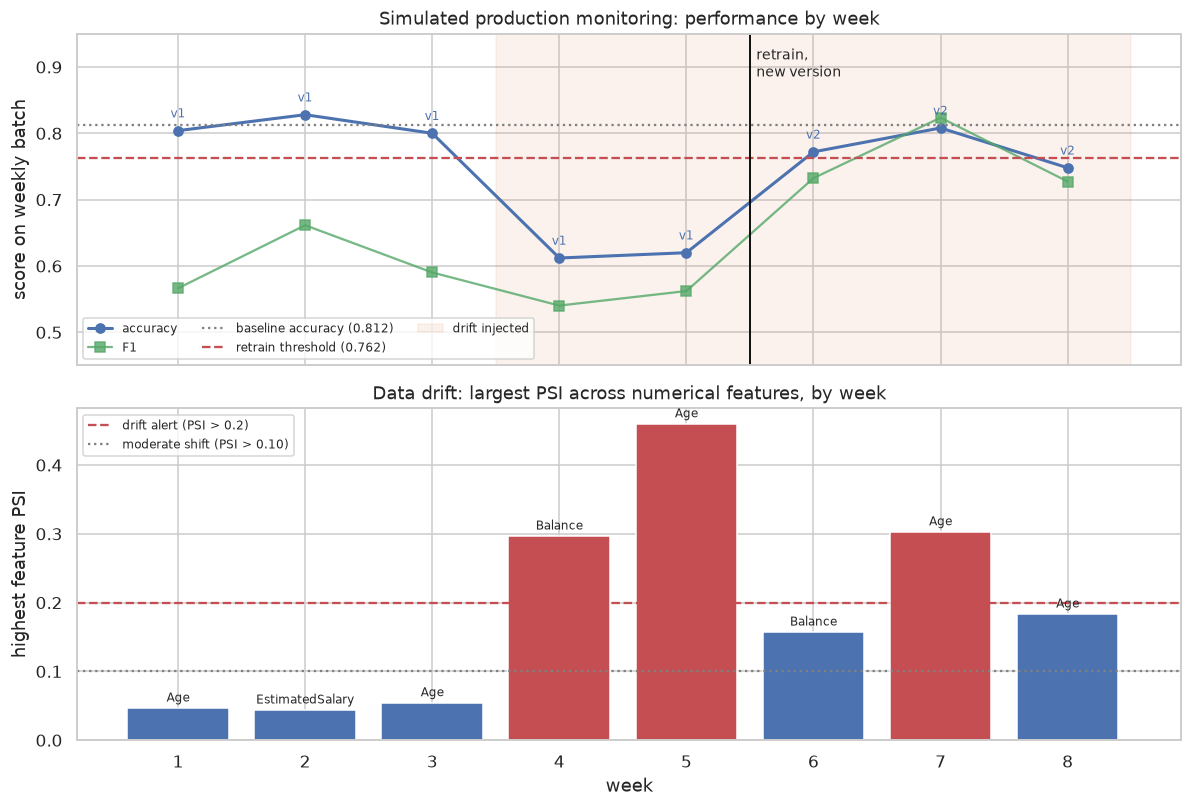

In [35]:
threshold = monitor_log["accuracy_threshold"].iloc[0]
baseline = threshold + config.ACCURACY_DROP_TOLERANCE
retrain_weeks = monitor_log.loc[monitor_log["retrain_triggered"], "week"].tolist()

fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)

ax = axes[0]
ax.plot(monitor_log["week"], monitor_log["accuracy"], marker="o", linewidth=2, color="#4C72B0", label="accuracy")
ax.plot(monitor_log["week"], monitor_log["f1"], marker="s", linewidth=1.5, color="#55A868", alpha=0.8, label="F1")
ax.axhline(baseline, color="gray", linestyle=":", label=f"baseline accuracy ({baseline:.3f})")
ax.axhline(threshold, color="#C44E52", linestyle="--", label=f"retrain threshold ({threshold:.3f})")
ax.axvspan(3.5, 8.5, color="#DD8452", alpha=0.10, label="drift injected")
for wk in retrain_weeks:
    ax.axvline(wk + 0.5, color="black", linewidth=1.2)
    ax.text(wk + 0.55, 0.93, "retrain,\nnew version", fontsize=9, va="top")
for _, r in monitor_log.iterrows():
    ax.text(r["week"], r["accuracy"] + 0.02, f"v{int(r['model_version'])}", ha="center", fontsize=8, color="#4C72B0")
ax.set_ylim(0.45, 0.95)
ax.set_ylabel("score on weekly batch")
ax.set_title("Simulated production monitoring: performance by week")
ax.legend(loc="lower left", ncol=3, fontsize=8)

ax = axes[1]
colors = ["#C44E52" if alert else "#4C72B0" for alert in monitor_log["drift_alert"]]
ax.bar(monitor_log["week"], monitor_log["max_psi"], color=colors)
ax.axhline(config.PSI_ALERT_THRESHOLD, color="#C44E52", linestyle="--", label=f"drift alert (PSI > {config.PSI_ALERT_THRESHOLD})")
ax.axhline(0.10, color="gray", linestyle=":", label="moderate shift (PSI > 0.10)")
for _, r in monitor_log.iterrows():
    ax.text(r["week"], r["max_psi"] + 0.01, r["most_drifted_feature"], ha="center", fontsize=8)
ax.set_xlabel("week")
ax.set_ylabel("highest feature PSI")
ax.set_title("Data drift: largest PSI across numerical features, by week")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [36]:
# The monitoring runs and the retrained version are in MLflow too
champion_version = int(client.get_model_version_by_alias(config.REGISTERED_MODEL_NAME, "champion").version)
versions = client.search_model_versions(f"name='{config.REGISTERED_MODEL_NAME}'")
display(pd.DataFrame([{
    "version": int(v.version),
    "aliases": "champion" if int(v.version) == champion_version else "",
    "stage_tag": v.tags.get("stage", ""),
    "f1_at_registration": v.tags.get("f1", ""),
} for v in versions]).sort_values("version"))

mon_exp = mlflow.get_experiment_by_name(config.MONITOR_EXPERIMENT_NAME)
mon_runs = mlflow.search_runs(experiment_ids=[mon_exp.experiment_id], order_by=["attributes.start_time ASC"])
mon_runs[["tags.mlflow.runName", "tags.model_version", "metrics.accuracy", "metrics.f1", "metrics.max_psi", "tags.retrain_triggered"]]

,version,aliases,stage_tag,f1_at_registration
1,1,champion,initial_training,0.6130
0,2,,simulated_retrain_week_5,0.8000


,tags.mlflow.runName,tags.model_version,metrics.accuracy,metrics.f1,metrics.max_psi,tags.retrain_triggered
0,week_01,1,0.804,0.566,0.046,False
1,week_02,1,0.828,0.661,0.043,False
2,week_03,1,0.800,0.590,0.054,False
3,week_04,1,0.612,0.540,0.296,False
4,week_05,1,0.620,0.562,0.459,True
5,week_06,2,0.772,0.732,0.157,False
6,week_07,2,0.808,0.824,0.302,False
7,week_08,2,0.748,0.727,0.183,False


In [37]:
pre = monitor_log[~monitor_log["drift_injected"]]
hit = monitor_log[monitor_log["drift_injected"] & (monitor_log["model_version"] == monitor_log["model_version"].iloc[0])]
post = monitor_log[monitor_log["model_version"] != monitor_log["model_version"].iloc[0]]
lines = [
    f"- **Weeks {pre['week'].min()} to {pre['week'].max()} (normal operation):** accuracy holds between "
    f"{pre['accuracy'].min():.3f} and {pre['accuracy'].max():.3f}, in line with the {baseline:.3f} baseline, and the highest PSI is "
    f"{pre['max_psi'].max():.3f}, so no drift is flagged.",
    f"- **Drift arrives in week {hit['week'].min()}:** accuracy falls to {hit['accuracy'].min():.3f}, well under the "
    f"{threshold:.3f} threshold, and PSI jumps to {hit['max_psi'].max():.3f}, above the {config.PSI_ALERT_THRESHOLD} alert line. "
    f"The actual churn rate in these weeks is about {hit['actual_churn_rate'].mean():.0%} while the model predicts about "
    f"{hit['predicted_churn_rate'].mean():.0%}. The drift alert fires in the same week accuracy drops, and PSI does not need labels, "
    f"so in practice it would be the earlier warning.",
]
if retrain_weeks and len(post):
    lines.append(
        f"- **Retraining triggers after week {retrain_weeks[0]}**, the second low week in a row. The retrained model "
        f"(version {int(post['model_version'].iloc[0])}) averages {post['accuracy'].mean():.3f} accuracy and {post['f1'].mean():.3f} F1 "
        f"over the remaining weeks, compared with {hit['accuracy'].mean():.3f} and {hit['f1'].mean():.3f} for the old model on drifted data.")
    late_low = post[post["below_threshold"]]
    if len(late_low):
        lines.append(
            f"- Week {', '.join(str(w) for w in late_low['week'])} dips just under the threshold again "
            f"({late_low['accuracy'].iloc[0]:.3f}). With only 250 customers per batch, a few points of movement is normal noise, "
            f"and the 2-week rule correctly holds off on another retrain.")
else:
    lines.append("- No retraining was triggered in this run.")
lines.append("- PSI stays elevated after the retrain because the inputs are still different from the original training data. "
             "The model has adapted, but the reference distributions have not been refreshed, which a production setup would do at each retrain.")
display(Markdown("**What the simulation shows**\n\n" + "\n".join(lines)))

**What the simulation shows**

- **Weeks 1 to 3 (normal operation):** accuracy holds between 0.800 and 0.828, in line with the 0.812 baseline, and the highest PSI is 0.054, so no drift is flagged.
- **Drift arrives in week 4:** accuracy falls to 0.612, well under the 0.762 threshold, and PSI jumps to 0.459, above the 0.2 alert line. The actual churn rate in these weeks is about 49% while the model predicts about 37%. The drift alert fires in the same week accuracy drops, and PSI does not need labels, so in practice it would be the earlier warning.
- **Retraining triggers after week 5**, the second low week in a row. The retrained model (version 2) averages 0.776 accuracy and 0.761 F1 over the remaining weeks, compared with 0.616 and 0.551 for the old model on drifted data.
- Week 8 dips just under the threshold again (0.748). With only 250 customers per batch, a few points of movement is normal noise, and the 2-week rule correctly holds off on another retrain.
- PSI stays elevated after the retrain because the inputs are still different from the original training data. The model has adapted, but the reference distributions have not been refreshed, which a production setup would do at each retrain.

Because this drift scenario is made up, the retrained model is used only inside the simulation. It is registered in MLflow (tagged `simulated_retrain_week_N`) so the version history is visible, but the `champion` alias and the model file the API serves still point to the real version 1 model.

## Scheduling retraining

In production the monitor and the retraining check would run on a schedule instead of by hand. `src/retrain.py` is the scheduled job: it reads the monitoring log, retrains only if the rule above is met (or if `--force` is passed), and registers the new version. Any new labeled data dropped into `data/new_batches/` is included.

In [38]:
show_file("src/retrain.py", "python")

**`src/retrain.py`**

```python
"""Task 4 (step 5): scheduled retraining check.

Meant to be run on a schedule (cron example in the README). It reads the
monitoring log and retrains only when accuracy has stayed below the threshold
for RETRAIN_PATIENCE checks in a row, or when --force is passed.

    python -m src.retrain            # retrain only if monitoring says so
    python -m src.retrain --force    # retrain no matter what

Any labeled CSVs dropped into data/new_batches/ (same columns as the original
file) are added to the training data.
"""
from __future__ import annotations

import argparse

import pandas as pd

from src import config
from src.data_prep import clean, load_clean, split
from src.train import train_and_track


def retrain_needed() -> tuple[bool, str]:
    if not config.MONITOR_LOG_PATH.exists():
        return False, "no monitoring log yet"
    log = pd.read_csv(config.MONITOR_LOG_PATH)
    current = log[log["model_version"] == log["model_version"].iloc[-1]]
    recent = current.tail(config.RETRAIN_PATIENCE)
    if len(recent) < config.RETRAIN_PATIENCE:
        return False, "not enough checks on the current model version yet"
    low = (recent["accuracy"] < recent["accuracy_threshold"]).all()
    detail = f"last {config.RETRAIN_PATIENCE} accuracies: {recent['accuracy'].tolist()}, " \
             f"threshold {recent['accuracy_threshold'].iloc[-1]}"
    return bool(low), detail


def load_training_data() -> pd.DataFrame:
    frames = [load_clean()]
    for path in sorted((config.ROOT / "data" / "new_batches").glob("*.csv")):
        frames.append(clean(pd.read_csv(path)))
    return pd.concat(frames, ignore_index=True)


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__.splitlines()[0])
    parser.add_argument("--force", action="store_true", help="retrain even if accuracy is fine")
    args = parser.parse_args()

    needed, detail = retrain_needed()
    print(f"Monitoring check: {detail}")
    if not (needed or args.force):
        print("No retraining needed.")
        return

    X_train, X_test, y_train, y_test = split(load_training_data())
    out = train_and_track(X_train, y_train, X_test, y_test, run_tag="scheduled_retrain")
    print(f"Retrained. Best model: {out['best_name']} "
          f"(F1 {out['best_metrics']['f1']:.4f}), registered as "
          f"{config.REGISTERED_MODEL_NAME} v{out['registered_version']}")


if __name__ == "__main__":
    main()
```

In [39]:
from src.retrain import retrain_needed

needed, detail = retrain_needed()
print("Scheduled check ->", detail)
print("Retrain needed: ", needed)

Scheduled check -> last 2 accuracies: [0.808, 0.748], threshold 0.7625
Retrain needed:  False


A cron schedule for the two jobs (edit with `crontab -e`, adjust the path):

```cron
# Every Monday 2:00 AM: score last week's data and log accuracy and drift
0 2 * * 1  cd /path/to/incremental-capstone-mlops && python -m src.monitor >> logs/monitor.log 2>&1

# Every Monday 3:00 AM: retrain only if accuracy has stayed below the threshold
0 3 * * 1  cd /path/to/incremental-capstone-mlops && python -m src.retrain >> logs/retrain.log 2>&1

# First day of each month: retrain regardless, so the model never gets too stale
0 4 1 * *  cd /path/to/incremental-capstone-mlops && python -m src.retrain --force >> logs/retrain.log 2>&1
```

After a retrain, the rollout is `docker build -t churn-api:<new version> .` and replacing the running container.

---
# Summary

| Task | Outcome |
|---|---|
| 1. Churn data | 10,000 customers, no missing values, one header problem fixed, 20.4% churn. Age, Germany, inactivity, and product count drive churn. |
| 2. Models | Four models trained and compared on Accuracy, Precision, Recall, and F1. The best model by F1 is selected automatically and saved (see the Task 2 results above). |
| 3. Experiments | Every run logged to MLflow with parameters, metrics, and the model. Best model registered as `churn-prediction-model` with the `champion` alias. |
| 4. Operations | FastAPI service with single and batch prediction, Dockerfile, simulated monitoring with PSI drift checks, and automatic retraining when accuracy drops. |

**Limits worth stating:** the monitoring data is simulated, so the drift and recovery numbers show that the process works, not how the model would behave with real customers. Weekly batches of 250 are small, so week-to-week accuracy moves a few points from noise alone, which is the reason for the 2-week rule. The decision threshold was left at the default 0.5, and tuning it to the cost of a missed churner versus an unneeded retention offer would be the next improvement.